# Introducción teórica

## Filtrado digital de señales

Los filtros digitales se pueden clasificar principalmente en dos categorías: filtros de respuesta al impulso finita (FIR) y filtros de respuesta al impulso infinita (IIR).

## Filtros FIR (Finite Impulse Response)

Los filtros FIR se caracterizan por tener una respuesta al impulso de duración finita. Su salida depende exclusivamente de un número finito de muestras presentes y pasadas de la entrada.

Su ecuación en diferencias es:

$$
y[n]=\sum_{k=0}^{M}b_kx[n-k]
$$

Donde $x[n]$ representa la señal de entrada, $y[n]$ la señal de salida y $b_k$ los coeficientes del filtro.

Su función de transferencia puede expresarse como:

$$
H(z)=\sum_{k=0}^{M}b_kz^{-k}
$$

Los filtros FIR  no poseen realimentación, por lo que su estabilidad está garantizada para coeficientes finitos.

Además, Estos filtros pueden ser diseñados para tener fase lineal . Esto significa que todas las componentes frecuenciales sufren el mismo retardo temporal, evitando la distorsión de fase.

Como desventaja, generalmente requieren un orden mayor que los filtros IIR para conseguir especificaciones de atenuación y transición equivalentes, lo que puede incrementar el costo computacional.

## Filtros IIR (Infinite Impulse Response)

Los filtros IIR a diferencia de los FIR, utilizan realimentación: su salida depende tanto de muestras presentes y pasadas de la entrada como de muestras anteriores de la propia salida.

Su ecuación en diferencias general es:

$$
y[n]=\sum_{k=0}^{M}b_kx[n-k]
-\sum_{k=1}^{N}a_ky[n-k]
$$

Su función de transferencia está dada por:

$$
H(z)=
\frac{\sum_{k=0}^{M}b_kz^{-k}}
{1+\sum_{k=1}^{N}a_kz^{-k}}
$$

La presencia de realimentación permite obtener respuestas frecuenciales selectivas con órdenes relativamente bajos. Por este motivo, los filtros IIR suelen presentar un menor costo computacional que los FIR para determinadas especificaciones de filtrado.

Su estabilidad depende de la ubicación de sus polos en el plano. Para que un filtro IIR causal sea estable, todos sus polos deben encontrarse estrictamente dentro del círculo unitario en el plano Z.

Una de sus principales desventajas es que generalmente presentan una respuesta de fase no lineal, lo que puede producir distorsiones temporales en señales.

##  Diseño de filtros IIR

Para diseñar un filtro digital es necesario establecer previamente una plantilla de especificaciones frecuenciales. Esta define las condiciones que debe cumplir la respuesta en magnitud del filtro:

- Frecuencia de borde de banda pasante ($w_p$): determina hasta dónde se desea conservar la señal.
- Frecuencia de borde de banda de rechazo ($w_s$): establece a partir de qué frecuencia se exige una atenuación determinada.
- Atenuación máxima en banda pasante ($G_{pass}$): determina la máxima variación permitida en la banda de paso.
- Atenuación mínima en banda de rechazo ($G_{stop}$): determina la atenuación mínima exigida para las componentes no deseadas.

La atenuación en decibeles se define como:

$$
A(f)=-20\log_{10}|H(f)|
$$

Por lo tanto, una mayor atenuación implica una menor amplitud de las componentes frecuenciales a la salida.

La función `iirdesign` de la biblioteca SciPy permite diseñar filtros IIR a partir de estas especificaciones, calculando el orden y los coeficientes necesarios para satisfacer la plantilla establecida.

En la práctica, no es posible implementar un filtro ideal, ya que requeriría una transición instantánea entre la banda pasante y la banda de rechazo, lo que implica una respuesta al impulso de duración infinita. Por este motivo, se utilizan distintas aproximaciones matemáticas que permiten obtener filtros realizables y cuyas respuestas en magnitud se aproximan a las especificaciones deseadas.

Entre las aproximaciones utilizadas se encuentran Butterworth, Chebyshev  I, Chebyshev  II y elíptica (Cauer). Cada una presenta diferentes características en cuanto a la planicidad de la banda pasante, el ripple permitido, la atenuación en la banda de rechazo y la selectividad frecuencial. 

Estas aproximaciones permiten controlar  la respuesta en magnitud. Por lo tanto, aunque el filtro cumpla las especificaciones de amplitud, puede introducir distorsiones de fase que modifiquen la forma temporal de la señal.

##  Representación mediante secciones de segundo orden (SOS)

La función de transferencia de un filtro IIR de orden elevado puede representarse como una única función racional con  polos y ceros. Sin embargo, implementar directamente sus coeficientes puede generar problemas de precisión numérica y errores de redondeo. Esto se debe, en parte, a la presencia de realimentación, los errores numéricos introducidos durante los cálculos pueden propagarse a través de las sucesivas iteraciones del sistema. Pequeñas variaciones en los coeficientes pueden modificar la ubicación de los polos y, por lo tanto, alterar significativamente la respuesta del filtro e incluso comprometer su estabilidad.

Para reducir estos problemas se utiliza una representación en cascada de secciones de segundo orden (SOS, Second-Order Sections).

En esta representación, la función de transferencia total se expresa como el producto de funciones de segundo orden:

$$
H(z)=\prod_{i=1}^{K}H_i(z)
$$

Cada sección tiene la forma:

$$
H_i(z)=
\frac{b_{0,i}+b_{1,i}z^{-1}+b_{2,i}z^{-2}}
{a_{0,i}+a_{1,i}z^{-1}+a_{2,i}z^{-2}}
$$

La representación SOS mejora la robustez numérica durante la implementación, especialmente en filtros de orden elevado, al reducir los problemas asociados a la representación directa de polinomios de alto grado.

En SciPy, el parámetro `output='sos'` permite obtener directamente esta representación.


## Filtrado bidireccional: función `filtfilt`

El filtrado convencional de un sistema causal introduce la respuesta de fase propia del filtro. Para aplicaciones en las que se dispone de la señal completa y no se requiere procesamiento en tiempo real, puede utilizarse un filtrado bidireccional.

La función `filtfilt` realiza dos pasadas sobre la señal

Conceptualmente, la respuesta total en frecuencia resulta:

$$
H_{total}(e^{j\omega})=
H(e^{j\omega})H(e^{-j\omega})
$$

Para filtros con coeficientes reales:

$$
H_{total}(e^{j\omega})=|H(e^{j\omega})|^2
$$

La fase se cancela y se obtiene una respuesta de fase nula, evitando el desplazamiento temporal de las componentes frecuenciales en la región interior de la señal.

Sin embargo, como consecuencia de aplicar el filtro dos veces, el módulo de la respuesta se eleva al cuadrado. Por lo tanto, la atenuación expresada en decibeles se duplica, al igual que las variaciones de magnitud en la banda pasante.

Esto implica que la respuesta final ya no satisface necesariamente la plantilla original del filtro.
Por estas razones, el filtrado bidireccional resulta especialmente útil en el procesamiento y análisis fuera de línea de señales ECG, cuando se busca eliminar la distorsión de fase.

# A) Diseño de la plantilla de filtrado digital

Antes de diseñar los filtros, se realiza un análisis de la señal ECG contaminada en los dominios temporal y frecuencial.

En primer lugar, se observa la señal en el dominio temporal para identificar sus características generales. Posteriormente, se estima su densidad espectral de potencia mediante el periodograma modificado y el método de Welch.

Cantidad de muestras: 1129116
Duracion: 1129.116 segundos
Minimo: -32768.0
Maximo: 32767.0
Desvio estandar: 4914.7025077897015


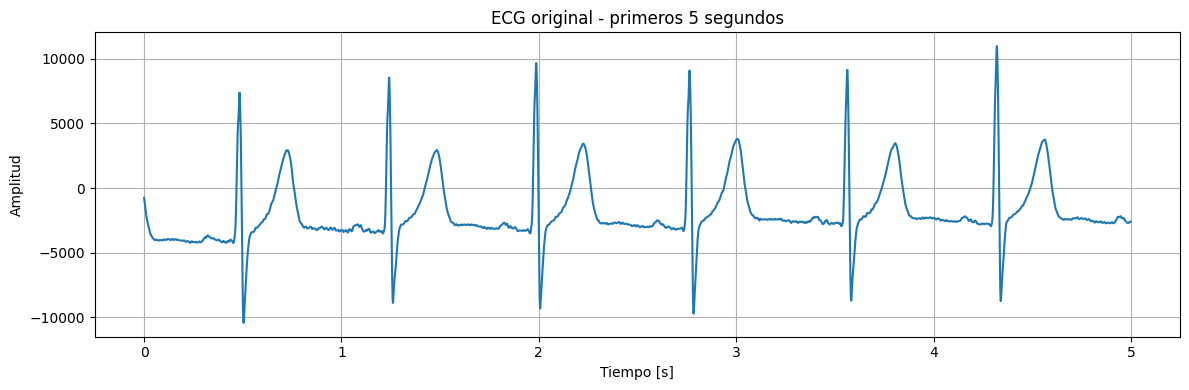

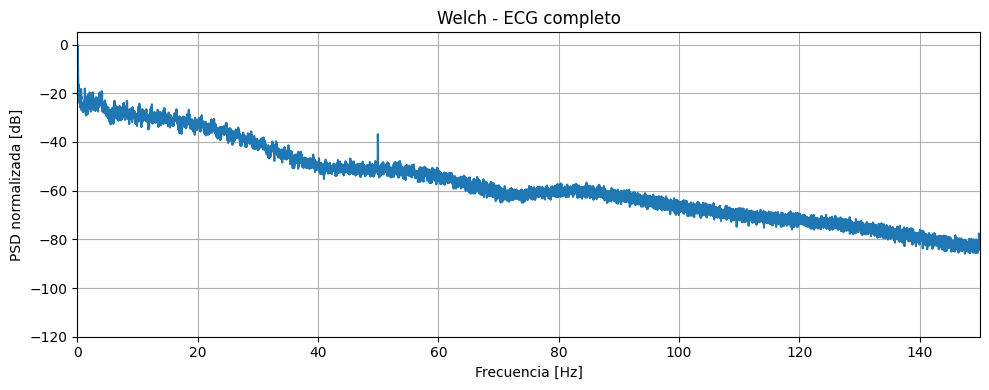

In [2]:
#%% IMPORTACION DE MODULOS

import numpy as np
import matplotlib.pyplot as plt
import scipy.io as sio
from scipy import signal as sig


#%% PARAMETROS

fs_ecg = 1000  # Frecuencia de muestreo [Hz]


#%% LECTURA DE ECG

mat_struct = sio.loadmat('./ECG_TP4.mat')

ecg_one_lead = mat_struct['ecg_lead'].flatten().astype(float)

N = len(ecg_one_lead)

print('Cantidad de muestras:', N)
print('Duracion:', N/fs_ecg, 'segundos')
print('Minimo:', np.min(ecg_one_lead))
print('Maximo:', np.max(ecg_one_lead))
print('Desvio estandar:', np.std(ecg_one_lead))


#%% VISUALIZACION DEL ECG

N_visual = 5000

t = np.arange(N_visual) / fs_ecg

plt.figure(figsize=(12, 4))
plt.plot(t, ecg_one_lead[:N_visual])

plt.xlabel('Tiempo [s]')
plt.ylabel('Amplitud')
plt.title('ECG original - primeros 5 segundos')
plt.grid()
plt.tight_layout()
plt.show()


#%% ELIMINAR COMPONENTE CONTINUA

ecg_sin_media = ecg_one_lead - np.mean(ecg_one_lead)


#%% METODO DE WELCH

cant_Promedio = 10

nperseg = N // cant_Promedio
nfft = 2 * nperseg

f_w, Pxx_w = sig.welch(
    ecg_sin_media,
    fs=fs_ecg,
    window='blackman',
    nperseg=nperseg,
    nfft=nfft
)


#%% NORMALIZACION EN dB

Pxx_w_db = 10 * np.log10(Pxx_w / np.max(Pxx_w))


#%% ESPECTRO GENERAL

plt.figure(figsize=(10, 4))

plt.plot(f_w, Pxx_w_db)

plt.xlabel('Frecuencia [Hz]')
plt.ylabel('PSD normalizada [dB]')
plt.title('Welch - ECG completo')
plt.xlim(0, 150)
plt.ylim(-120, 5)
plt.grid()
plt.tight_layout()
plt.show()


 

## Observaciones del espectro con ruido

A partir del análisis espectral mediante el método de Welch se identifican:

Una elevada concentración de potencia en las frecuencias bajas.

Un pico localizado aproximadamente en 50 Hz.

Una distribución de potencia decreciente hacia las frecuencias más elevadas, donde puede encontrarse ruido muscular y otros componentes de alta frecuencia como el ruido causado por el movimiento de los electrodos.


## Espesctro sin ruido

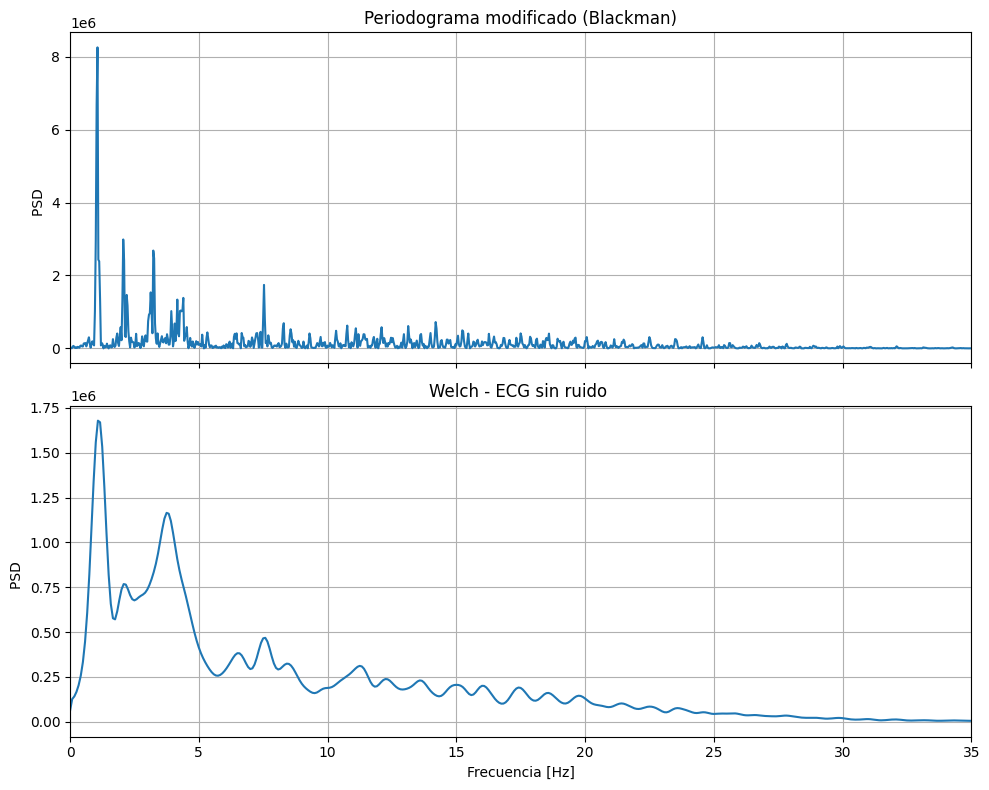

In [22]:
import numpy as np
from scipy import signal as sig
import matplotlib.pyplot as plt
import scipy.io as sio
from scipy.io import wavfile      # necesario para que sio.wavfile exista en algunas versiones

 

#%% Lectura de ECG sin ruido
fs_ecg = 1000  # Hz

x = np.load('ecg_sin_ruido.npy').flatten()
x = x - np.mean(x)                 # media nula (asumida)

#%% Referencia: varianza = potencia
P_var = np.var(x)

#%% Periodograma modificado



f_p, Pxx = sig.periodogram(x, fs=fs_ecg, window='blackman' )
 

#%% Welch 

cant_Promedio = 10

nperseg = x.shape[0] // cant_Promedio #Longitud / cantidad de promedios

nfft = 4 * nperseg # ZeroPadding

window = 'blackman'
f_w, Pxx_w = sig.welch( x, fs=fs_ecg, window = window  , nperseg=nperseg, nfft= nfft )



#%% Area

 #np.cumsum() 
 
 
#%% Gráficos (dos subplots en una ventana)
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8), sharex=True)

ax1.plot(f_p, Pxx)
ax1.set_ylabel('PSD  ')
ax1.set_title('Periodograma modificado (Blackman)')
ax1.set_xlim(0, 35)
ax1.grid()

ax2.plot(f_w, Pxx_w)
ax2.set_xlabel('Frecuencia [Hz]')
ax2.set_ylabel('PSD  ')
ax2.set_title(f'Welch - ECG sin ruido ')
ax2.grid()

fig.tight_layout()
plt.show()

### Análisis del ECG sin ruido 

A partir del espectro del ECG sin ruido, se puede observar que la mayor concentración de componentes frecuenciales se encuentra en el rango de bajas frecuencias, desde valores cercanos a 0 Hz hasta aproximadamente 30 Hz, aunque su magnitud disminuye progresivamente a medida que aumenta la frecuencia.

A partir de los 30 Hz, el contenido frecuencial se reduce, lo que indica que la mayor parte de la información del ECG se encuentra concentrada por debajo de ese valor.

Debido a esto se selecciona 30 Hz como referencia para establecer el límite superior de la banda de paso de la plantilla.

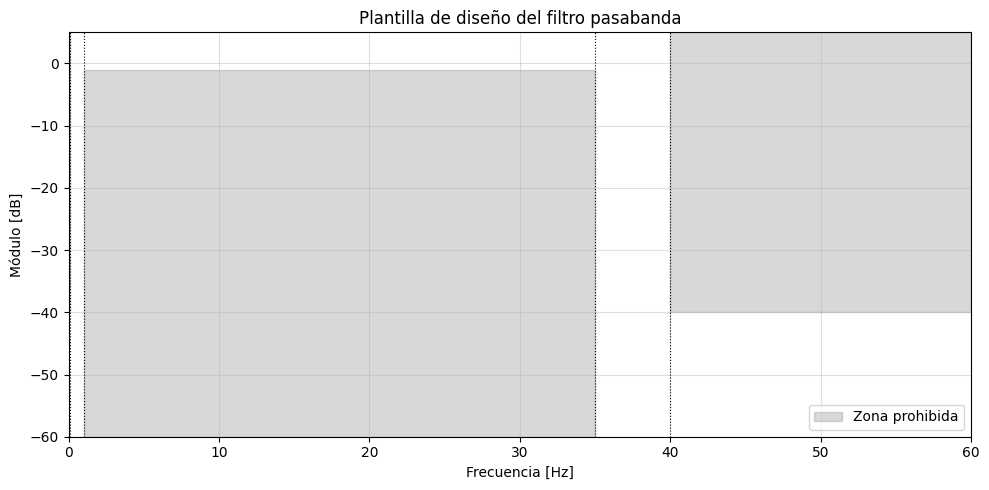

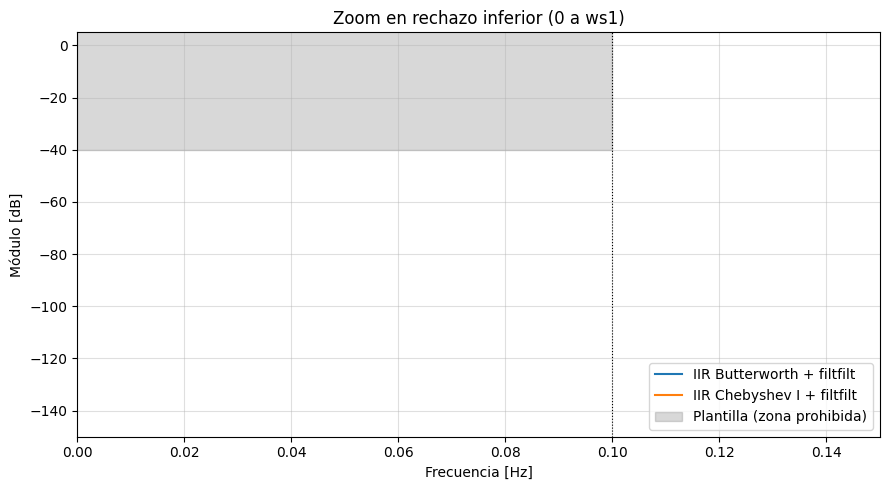

In [41]:

# ============================================================
# ITEM A - PLANTILLA DE DISEÑO PARA EL ECG
# ============================================================

import numpy as np
import scipy.io as sio
import matplotlib.pyplot as plt

#%% CARGA DEL ECG

mat_struct = sio.loadmat('./ECG_TP4.mat')

ecg = mat_struct['ecg_lead'].flatten()

fs = 1000
nyq_frec = fs / 2

#%% PLANTILLA DE DISEÑO

ripple = 1       # dB
atenuacion = 40  # dB

ws1 = 0.1  # Rechazo inferior
wp1 = 1    # Paso inferior
wp2 = 35   # Paso superior
ws2 = 40   # Rechazo superior

# Frecuencias normalizadas a Nyquist
frecs = np.array([
    0, ws1, wp1, wp2, ws2, nyq_frec
]) / nyq_frec

# Ganancias en dB
gains = np.array([
    -atenuacion,
    -atenuacion,
    -ripple,
    -ripple,
    -atenuacion,
    -atenuacion
])

# Conversión de dB a escala lineal
gains = 10**(gains / 20)
#%% REPRESENTACIÓN DE LA PLANTILLA

fmax = 60
ymin, ymax = -60, 5
gris = dict(color='gray', alpha=0.3)

plt.figure(figsize=(10, 5))

# Zonas prohibidas
plt.fill_between([0, ws1],      -atenuacion, ymax, **gris, label='Zona prohibida')
plt.fill_between([ws2, fmax],   -atenuacion, ymax, **gris)
plt.fill_between([wp1, wp2],    ymin,        -ripple, **gris)

# Límites de frecuencia
for f in [ws1, wp1, wp2, ws2]:
    plt.axvline(f, color='k', linestyle=':', linewidth=0.8)

plt.xlabel('Frecuencia [Hz]')
plt.ylabel('Módulo [dB]')
plt.title('Plantilla de diseño del filtro pasabanda')

plt.xlim(0, fmax)
plt.ylim(ymin, ymax)

plt.grid(alpha=0.4)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

#%% ZOOM EN LA BANDA DE RECHAZO INFERIOR (0 a ws1)

# Grilla fina solo en la zona de interés
f_zoom = np.linspace(0, 1.5 * ws1, 5000)

_, h_butter_z = sig.sosfreqz(sos_butter, worN=f_zoom, fs=fs)
_, h_cheby_z  = sig.sosfreqz(sos_cheby,  worN=f_zoom, fs=fs)

H_butter_z = 40 * np.log10(np.maximum(np.abs(h_butter_z), 1e-12))
H_cheby_z  = 40 * np.log10(np.maximum(np.abs(h_cheby_z),  1e-12))

gris = dict(color='gray', alpha=0.3)

plt.figure(figsize=(9, 5))

plt.plot(f_zoom, H_butter_z, label='IIR Butterworth + filtfilt')
plt.plot(f_zoom, H_cheby_z,  label='IIR Chebyshev I + filtfilt')

# Zona prohibida: de 0 a ws1 la ganancia debe ser < -atenuacion
plt.fill_between([0, ws1], -atenuacion, 100, **gris, label='Plantilla (zona prohibida)')

plt.axvline(ws1, color='k', linestyle=':', linewidth=0.8)

plt.xlim(0, 1.5 * ws1)
plt.ylim(-150, 5)

plt.xlabel('Frecuencia [Hz]')
plt.ylabel('Módulo [dB]')
plt.title('Zoom en rechazo inferior (0 a ws1)')
plt.grid(alpha=0.4)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

## B) Los valores de la plantilla

En primer lugar, se tomó como referencia el ancho de banda útil estimado en la **Tarea Semanal 5**, donde se analizó el contenido frecuencial del ECG sin ruido. A partir de este análisis se observó que la mayor concentración de componentes frecuenciales se encuentra por debajo de los 30 Hz, disminuyendo considerablemente a partir de ese valor. Por este motivo, se estableció una banda de paso comprendida entre 1 Hz y 35 Hz, buscando conservar las componentes relevantes de la señal.

Por otro lado, se definieron las bandas de rechazo para atenuar las componentes no deseadas:

- **Bajas frecuencias (0–0,1 Hz):** se busca reducir las variaciones lentas de la línea de base.
- **Altas frecuencias (40–500 Hz):** se busca atenuar las componentes de alta frecuencia asociadas principalmente al ruido muscular y otras interferencias.

Se establecieron bandas de transición entre 0,1 y 1 Hz, y entre 35 y 40 Hz, para permitir una atenuación progresiva sin exigir una transición abrupta.

Finalmente, se adoptaron las siguientes especificaciones:

- **Rizado máximo en banda de paso:** 1 dB, para limitar las variaciones de amplitud de la señal ECG.
- **Atenuación mínima en banda de rechazo:** 40 dB, para conseguir una reducción significativa de las componentes no deseadas.


## C) Filtros IIR 

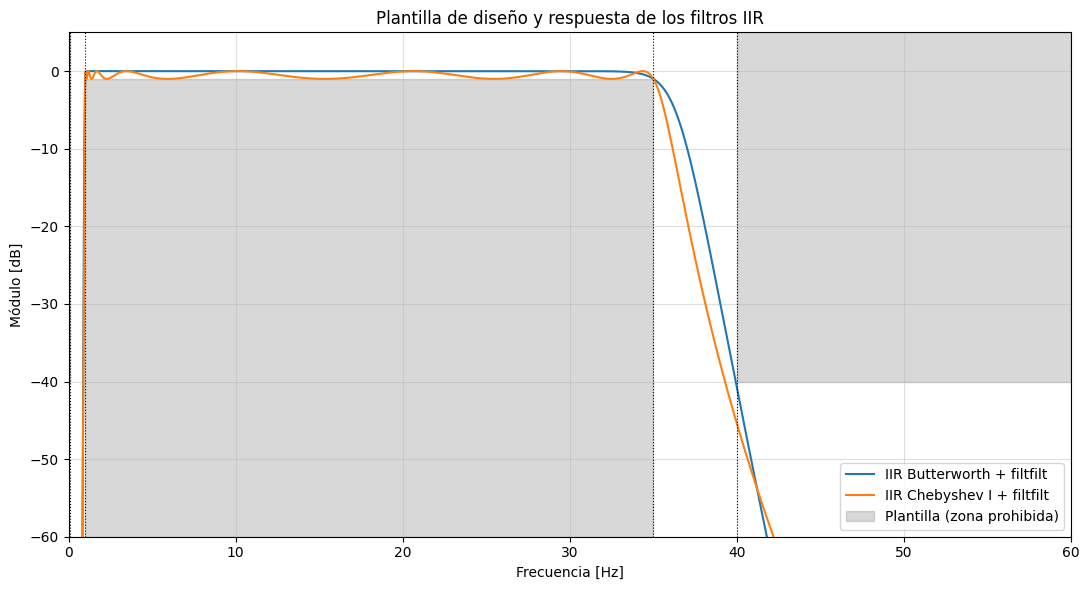

In [48]:
#%% RESPUESTA EN FRECUENCIA

f_butter, h_butter = sig.sosfreqz(sos_butter, worN=32768, fs=fs)
f_cheby,  h_cheby  = sig.sosfreqz(sos_cheby,  worN=32768, fs=fs)

# Ganancia en dB (negativa). Se multiplica por 2 (40·log10) porque
# filtfilt aplica el filtro hacia adelante y hacia atrás: |H|^2
H_butter_db = 40 * np.log10(np.maximum(np.abs(h_butter), 1e-12))
H_cheby_db  = 40 * np.log10(np.maximum(np.abs(h_cheby),  1e-12))


#%% REPRESENTACIÓN COMPARATIVA CON PLANTILLA

fmax = 60          # podés poner 100 como en tu otra figura
ymin, ymax = -60, 5

plt.figure(figsize=(11, 6))

plt.plot(f_butter, H_butter_db, label='IIR Butterworth + filtfilt')
plt.plot(f_cheby,  H_cheby_db,  label='IIR Chebyshev I + filtfilt')

# --- Plantilla: zonas prohibidas en gris ---
gris = dict(color='gray', alpha=0.3)

# Rechazo inferior (0 a ws1): la ganancia debe ser < -atenuacion
plt.fill_between([0, ws1], -atenuacion, ymax, **gris, label='Plantilla (zona prohibida)')

# Rechazo superior (desde ws2): la ganancia debe ser < -atenuacion
plt.fill_between([ws2, fmax], -atenuacion, ymax, **gris)

# Banda de paso: la ganancia debe ser > -ripple
plt.fill_between([wp1, wp2], ymin, -ripple, **gris)

# Líneas de frecuencias de la plantilla
for f in [ws1, wp1, wp2, ws2]:
    plt.axvline(f, color='k', linestyle=':', linewidth=0.8)

plt.xlim(0, fmax)
plt.ylim(ymin, ymax)

plt.xlabel('Frecuencia [Hz]')
plt.ylabel('Módulo [dB]')
plt.title('Plantilla de diseño y respuesta de los filtros IIR')

plt.grid(alpha=0.4)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()